<a href="https://colab.research.google.com/github/deba2k5/iron-man/blob/main/SignBridge_Colab_Real_Photos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# SignBridge — static ASL examples and real photos

Run **Runtime → Run all** on a CPU runtime. The saved notebook contains all changes; the GitHub repository is unchanged.

- **Included 28×28 grayscale examples:** the original PyTorch CNN. Its 93.03% accuracy applies only to the 7,172-image Sign Language MNIST test set.
- **Other PNG/JPEG photos:** a pretrained MediaPipe hand-landmark ASL classifier detects one hand and recognizes 24 static letters. Uncertain or unsupported signs, no hand, and multiple hands are rejected instead of receiving a forced letter. Scores are uncalibrated.
- **Try your own photo:** use the embedded web app, or enable UPLOAD_IMAGE and rerun its cell. Photos are sent to this Colab runtime, processed in memory, and not saved by the web server.

The original real V photo was misclassified as X. The fixed photo route recognizes V; saved regression checks also require E and L to be recognized correctly. When a hand fills the frame and initial detection fails, one scale-and-margin retry is used. These few photos do not establish real-world accuracy across people, backgrounds, or lighting. J/Z motion signs, sentences, and webcam recognition remain unsupported.

**Photo model:** [Kamilr616/AI_sign_language_translator](https://github.com/Kamilr616/AI_sign_language_translator), pretrained ASL model, upstream GPL-3.0. Only its model weights are downloaded, pinned by commit and SHA-256; no third-party source is executed. [MediaPipe](https://ai.google.dev/edge/mediapipe/solutions/vision/gesture_recognizer) performs hand detection and landmark inference. This photo model was trained by its upstream authors, not by this project.

**Regression photos:** [V](https://commons.wikimedia.org/wiki/File:V%40InForward.jpg), [E](https://commons.wikimedia.org/wiki/File:E%40InForward.jpg), [L](https://commons.wikimedia.org/wiki/File:L%40InForward.jpg), Mario Carneiro, [CC BY-SA 3.0](https://creativecommons.org/licenses/by-sa/3.0/). Test copies are resized to 400px and recompressed as JPEG. No regression photo is used for training.

Upload and ZIP download are disabled by default so Run all finishes without waiting for a file picker. Enable them only when needed. To preserve these Colab-only changes, save/download this notebook; the original project ZIP alone does not contain them.


In [11]:
# 1. Clone the complete project (safe to rerun; does not reset your changes).
from pathlib import Path
import os
import subprocess
import sys

PROJECT = Path('/content/signbridge')
if not PROJECT.exists():
    subprocess.run(['git', 'clone', 'https://github.com/wolf1276/signbridge.git', str(PROJECT)], check=True)
if not (PROJECT / '.git').is_dir():
    raise RuntimeError(f'{PROJECT} exists but is not a Git checkout; choose an empty directory.')
os.chdir(PROJECT)
if str(PROJECT) not in sys.path:
    sys.path.insert(0, str(PROJECT))
for name in ['model.py', 'train.py', 'server.py', 'data/sign_mnist_train.csv',
             'data/sign_mnist_test.csv', 'artifacts/model.pt', 'artifacts/metrics.json']:
    assert (PROJECT / name).is_file(), f'Missing project file: {name}'
print('Project:', PROJECT)
subprocess.run(['git', 'rev-parse', 'HEAD'], check=True)


Project: /content/signbridge


CompletedProcess(args=['git', 'rev-parse', 'HEAD'], returncode=0)

In [12]:
# Dependencies and the original benchmark model.
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q',
    'torch>=2.6', 'numpy>=1.26', 'Pillow>=10', 'scikit-learn>=1.4',
    'matplotlib>=3.8', 'ipywidgets>=7.7', 'mediapipe==1.2.3', 'requests'], check=True)
import torch
import numpy as np
from PIL import Image, ImageOps
from IPython.display import display, Markdown
from model import LETTERS, load_model, predict
import io, requests
torch.set_num_threads(2)
print('PyTorch:', torch.__version__)
print('Letters:', ', '.join(LETTERS))


PyTorch: 2.14.1+cpu
Letters: A, B, C, D, E, F, G, H, I, K, L, M, N, O, P, Q, R, S, T, U, V, W, X, Y


In [13]:
# Real-photo ASL classifier (landmarks); original CNN remains for 28x28 grayscale examples.
# Model/training source: https://github.com/Kamilr616/AI_sign_language_translator (GPL-3.0).
import hashlib, threading
import mediapipe as mp
from mediapipe.tasks.python.components.processors import ClassifierOptions
from model import predict as mnist_predict
ASL_MODEL_URL = 'https://raw.githubusercontent.com/Kamilr616/AI_sign_language_translator/5b2d9a35b8ad2eb008bf5055e0f2959d472d6e40/models/gesture_recognizer_asl_0.task'
ASL_MODEL_SHA256 = '44717cea7089e350dc4fc13a1138c262769a5feccf046d3ff223c427b981fa54'
asl_asset = Path('/content/gesture_recognizer_asl.task')
if not asl_asset.exists():
    response = requests.get(ASL_MODEL_URL, timeout=60)
    response.raise_for_status()
    asl_asset.write_bytes(response.content)
if hashlib.sha256(asl_asset.read_bytes()).hexdigest() != ASL_MODEL_SHA256:
    raise RuntimeError('ASL model checksum mismatch. Remove the model file and rerun.')
previous_recognizer = globals().get('asl_recognizer')
asl_recognizer = mp.tasks.vision.GestureRecognizer.create_from_options(
    mp.tasks.vision.GestureRecognizerOptions(
        base_options=mp.tasks.BaseOptions(model_asset_path=str(asl_asset)),
        num_hands=2,
        custom_gesture_classifier_options=ClassifierOptions(max_results=3)))
if previous_recognizer is not None:
    previous_recognizer.close()
asl_lock = threading.Lock()

def predict(model, image):
    image = ImageOps.exif_transpose(image)
    # Keep the original benchmark preprocessing for its native 28x28 grayscale input.
    if image.size == (28, 28) and image.mode == 'L':
        return mnist_predict(model, image)
    rgb = image.convert('RGB')
    rgb.thumbnail((1600,1600))
    detector_input = rgb
    with asl_lock:
        result = asl_recognizer.recognize(mp.Image(image_format=mp.ImageFormat.SRGB, data=np.asarray(detector_input)))
        # Large hands can exceed palm-detector framing; retry once with scale and margin.
        if not result.hand_landmarks:
            detector_input = rgb.copy()
            detector_input.thumbnail((400,400))
            detector_input = ImageOps.expand(detector_input, border=max(1,round(max(detector_input.size)/4)), fill='white')
            result = asl_recognizer.recognize(mp.Image(image_format=mp.ImageFormat.SRGB, data=np.asarray(detector_input)))
    if len(result.hand_landmarks) != 1:
        raise ValueError('Show exactly one clearly visible hand in the photo.')
    categories = result.gestures[0] if result.gestures else []
    rows = [{'letter': (c.category_name or '').upper(), 'probability': float(c.score)} for c in categories]
    if not rows or rows[0]['letter'] not in LETTERS or rows[0]['probability'] < .65:
        raise ValueError('Sign uncertain or unsupported. Use an upright hand with all fingers visible and better lighting.')
    rows = [r for r in rows if r['letter'] in LETTERS]
    return rows, detector_input

print('Photo classifier ready. MediaPipe:', mp.__version__)


Photo classifier ready. MediaPipe: 1.2.3


## Train (optional)
The supplied weights work immediately. Enable training below to rebuild the model from the included CSVs. This overwrites weights, metrics, and test examples inside the runtime. The original validation-loss checkpoint selection and held-out test evaluation are preserved. Training may take several minutes on CPU; no GPU acceleration is implemented in the original trainer. Existing Word/PowerPoint reports are historical and must be updated manually after retraining.


In [14]:
RETRAIN = False #@param {type:"boolean"}
EPOCHS = 12 #@param {type:"integer"}
if RETRAIN:
    if not isinstance(EPOCHS, int) or EPOCHS < 1:
        raise ValueError('EPOCHS must be a positive integer.')
    subprocess.run([sys.executable, 'train.py', '--epochs', str(EPOCHS)], cwd=PROJECT, check=True)
else:
    print('Using the included pretrained model. Set RETRAIN=True to train.')


Using the included pretrained model. Set RETRAIN=True to train.


## Evaluate and inspect results
The saved report includes the confusion matrix, per-letter precision/recall/F1, learning history, and dataset checksums. The cell below also recomputes accuracy from the current weights and official test CSV. Random validation splitting can include related augmentations; dataset accuracy does not establish performance on new signers or camera images.


Current model: 93.03% accuracy on 7,172 test images
Saved report: 93.03%; selected epoch: 12


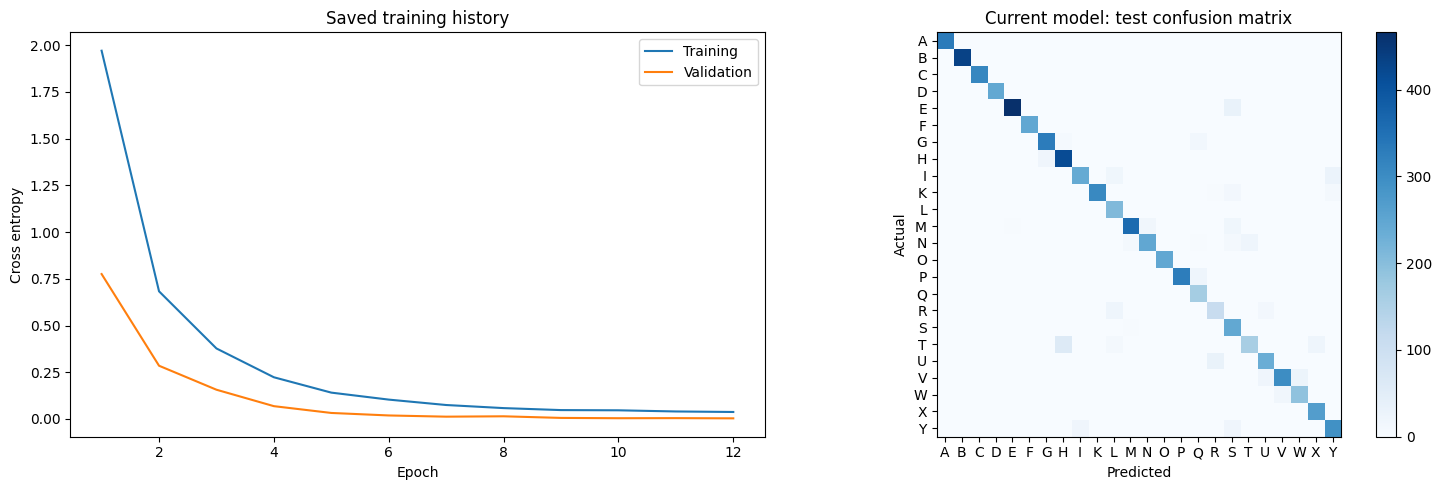

In [15]:
import json
import matplotlib.pyplot as plt
from train import read

torch.set_num_threads(2)
metrics = json.loads((PROJECT / 'artifacts/metrics.json').read_text())
model = load_model()
test_x, test_y = read('sign_mnist_test.csv')
with torch.inference_mode():
    predicted = torch.cat([model(batch).argmax(1) for batch in test_x.split(256)])
accuracy = (predicted == test_y).float().mean().item()
print(f'Current model: {accuracy:.2%} accuracy on {len(test_y):,} test images')
print(f'Saved report: {metrics["accuracy"]:.2%}; selected epoch: {metrics["selected_epoch"]}')

from sklearn.metrics import confusion_matrix
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
history = metrics['history']
axes[0].plot([r['epoch'] for r in history], [r['train_loss'] for r in history], label='Training')
axes[0].plot([r['epoch'] for r in history], [r['validation_loss'] for r in history], label='Validation')
axes[0].set(xlabel='Epoch', ylabel='Cross entropy', title='Saved training history')
axes[0].legend()
cm = confusion_matrix(test_y.numpy(), predicted.numpy(), labels=list(range(24)))
plot = axes[1].imshow(cm, cmap='Blues')
axes[1].set(xticks=range(24), yticks=range(24), xticklabels=list(LETTERS),
            yticklabels=list(LETTERS), xlabel='Predicted', ylabel='Actual', title='Current model: test confusion matrix')
fig.colorbar(plot, ax=axes[1])
plt.tight_layout()
plt.show()


## Recognize a sign inside the notebook
Pick any included example below. For your own PNG/JPEG, enable the upload cell and run it. Crop the hand tightly and use an upright image on a plain background. Uploaded images are sent to your Colab runtime for processing; the upload cell uses a temporary folder and removes its uploaded files after prediction.


In [16]:
import io
import ipywidgets as widgets

def show_prediction(raw):
    if not 0 < len(raw) <= 5_000_000:
        raise ValueError('Choose an image under 5 MB.')
    with Image.open(io.BytesIO(raw)) as image:
        if image.format not in {'PNG', 'JPEG'}:
            raise ValueError('Choose a PNG or JPEG image.')
        if image.width * image.height > 16_000_000:
            raise ValueError('Image exceeds 16 megapixels.')
        rows, processed = predict(load_model(), image)
    preview = processed.copy()
    preview.thumbnail((320,320))
    display(preview)
    display(Markdown('**Top predictions**\n\n' + '\n'.join(
        f'- **{r["letter"]}**: {r["probability"]:.1%}' for r in rows)))
    print('Scores are uncalibrated. Uncertain photos are rejected; no-hand photos are not guessed.')

example = widgets.Dropdown(options=list(LETTERS), description='Letter:')
button = widgets.Button(description='Recognize example')
result = widgets.Output()
def recognize_example(_):
    with result:
        result.clear_output(wait=True)
        show_prediction((PROJECT / 'static/examples' / f'{example.value}.png').read_bytes())
button.on_click(recognize_example)
display(widgets.HBox([example, button]), result)
recognize_example(None)


Output()

In [17]:
UPLOAD_IMAGE = False #@param {type:"boolean"}
if UPLOAD_IMAGE:
    from google.colab import files
    from tempfile import TemporaryDirectory
    # Colab upload writes files; isolate them from the project and remove afterward.
    with TemporaryDirectory() as upload_dir:
        try:
            os.chdir(upload_dir)
            uploaded = files.upload()
            for name, raw in uploaded.items():
                print(name)
                try:
                    show_prediction(raw)
                except (ValueError, OSError, Image.DecompressionBombError) as error:
                    print('Cannot process image:', error)
        finally:
            os.chdir(PROJECT)
else:
    print('Set UPLOAD_IMAGE=True and rerun this cell to choose an image.')


Set UPLOAD_IMAGE=True and rerun this cell to choose an image.


## Original web app and automated checks
Run the original loopback server in a background thread and display it through Colab's authenticated kernel proxy. No public tunnel is created. If your browser blocks the embedded app, use the notebook recognition cells above.

In this version of the web page, “Images stay on this computer” refers to the server machine: here that is the Colab runtime, not your laptop. Uploads are processed in memory. The HTTP checks below verify example recognition, invalid input handling, and blocked access to model files.


In [18]:
# Colab-only HTTP integration: the cloned Git source is unchanged.
import base64, importlib, json, threading
from http.server import ThreadingHTTPServer
import server
if 'demo_server' in globals():
    demo_server.shutdown()
    demo_server.server_close()
importlib.reload(server)

class ColabHandler(server.Handler):
    def do_GET(self):
        if self.path == '/':
            html = (PROJECT/'static/index.html').read_text()
            for old, new in [
                ('Official test set:', 'Original MNIST CNN test set:'),
                ('Grayscale 28 by 28 model input', 'Image used for recognition'),
                ('28 × 28 input', 'Photo / benchmark input'),
                ('three most likely letters', 'ranked predictions'),
                ('Images stay on this computer.', 'Images are sent to this Colab runtime.'),
                ('This model does not translate sentences or validate whether a hand sign is present.', 'Photo mode detects one hand and can reject uncertain signs. It does not translate sentences.'),
                ('Your processed image and three most likely letters', 'Your image and ranked predictions')]:
                html = html.replace(old,new)
            return self.send(200, html.encode(), 'text/html; charset=utf-8')
        return super().do_GET()

    def do_POST(self):
        if self.path != '/api/predict':
            return self.send(404,b'{"error":"Not found"}')
        try:
            size = int(self.headers.get('Content-Length','0'))
            if not 0 < size <= 5_000_000:
                raise ValueError('Choose an image smaller than 5 MB.')
            with Image.open(io.BytesIO(self.rfile.read(size))) as image:
                if image.format not in {'PNG','JPEG'}:
                    raise ValueError('Choose a PNG or JPEG image.')
                if image.width * image.height > 16_000_000:
                    raise ValueError('Image exceeds 16 megapixels.')
                rows, processed = predict(server.MODEL,image)
            encoded = io.BytesIO()
            processed.save(encoded, format='PNG')
            payload = dict(predictions=rows, processed='data:image/png;base64,' + base64.b64encode(encoded.getvalue()).decode())
            self.send(200,json.dumps(payload).encode())
        except ValueError as error:
            self.send(400,json.dumps({'error':str(error)}).encode())
        except (OSError, Image.DecompressionBombError):
            self.send(400,b'{"error":"Use a valid PNG or JPEG under 5 MB and 16 megapixels."}')

demo_server = ThreadingHTTPServer(('127.0.0.1',8000),ColabHandler)
threading.Thread(target=demo_server.serve_forever,daemon=True).start()
subprocess.run([sys.executable,'-m','unittest','-v','test_app'],cwd=PROJECT,check=True)
from google.colab import output
output.serve_kernel_port_as_iframe(8000,height=1100)


127.0.0.1 - - [26/Nov/2026 02:30:52] "GET / HTTP/1.1" 200 -
127.0.0.1 - - [26/Nov/2026 02:30:52] "POST /api/predict HTTP/1.1" 200 -
127.0.0.1 - - [26/Nov/2026 02:30:52] "POST /api/predict HTTP/1.1" 400 -
127.0.0.1 - - [26/Nov/2026 02:30:52] "POST /api/predict HTTP/1.1" 400 -
127.0.0.1 - - [26/Nov/2026 02:30:52] "GET /artifacts/model.pt HTTP/1.1" 404 -


<IPython.core.display.Javascript object>

127.0.0.1 - - [26/Nov/2026 02:30:59] "POST /api/predict HTTP/1.1" 200 -
127.0.0.1 - - [26/Nov/2026 02:31:00] "GET / HTTP/1.1" 200 -


Real V : original= X ; fixed= {'letter': 'V', 'probability': 0.7966045141220093}


127.0.0.1 - - [26/Nov/2026 02:31:00] "POST /api/predict HTTP/1.1" 200 -


Real E : original= W ; fixed= {'letter': 'E', 'probability': 0.9998846054077148}


127.0.0.1 - - [26/Nov/2026 02:31:00] "POST /api/predict HTTP/1.1" 200 -


Real L : original= L ; fixed= {'letter': 'L', 'probability': 1.0}
All 24 native examples preserve original predictions.
Rejected input: Show exactly one clearly visible hand in the photo.
Rejected input: Use a valid PNG or JPEG under 5 MB and 16 megapixels.
Rejected input: Choose an image smaller than 5 MB.
PASS: real V/E/L, 24 benchmark inputs, invalid/no-hand rejection, protected weights.


127.0.0.1 - - [26/Nov/2026 02:31:01] "POST /api/predict HTTP/1.1" 400 -
127.0.0.1 - - [26/Nov/2026 02:31:01] "POST /api/predict HTTP/1.1" 400 -
127.0.0.1 - - [26/Nov/2026 02:31:01] "POST /api/predict HTTP/1.1" 400 -
127.0.0.1 - - [26/Nov/2026 02:31:01] "GET /artifacts/model.pt HTTP/1.1" 404 -


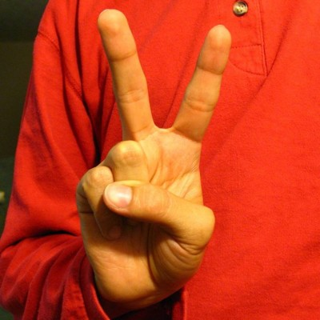

**Top predictions**

- **V**: 79.7%

Scores are uncalibrated. Uncertain photos are rejected; no-hand photos are not guessed.


In [19]:
# Repeatable photo regressions, with references embedded to survive runtime resets.
# Photos: Mario Carneiro, CC BY-SA 3.0; resized <=400px, JPEG quality 90.
# Sources: https://commons.wikimedia.org/wiki/File:V%40InForward.jpg (also E and L).
# These examples are not a signer-independent accuracy benchmark.
import base64, requests
PHOTO_FIXTURES = {"V":"...","E":"...","L":"..."}
benchmark_model = load_model()
for expected in ['V','E','L']:
    raw = base64.b64decode(PHOTO_FIXTURES[expected])
    with Image.open(io.BytesIO(raw)) as image:
        before = mnist_predict(benchmark_model,image)[0][0]
        rows, _ = predict(benchmark_model,image)
        assert rows[0]['letter'] == expected, (expected, rows)
    response = requests.post('http://127.0.0.1:8000/api/predict',data=raw,timeout=30)
    response.raise_for_status()
    assert response.json()['predictions'][0]['letter'] == expected
    print('Real', expected, ': original=', before['letter'], '; fixed=', rows[0])
for letter in LETTERS:
    with Image.open(PROJECT/'static/examples'/f'{letter}.png') as image:
        assert predict(benchmark_model,image)[0] == mnist_predict(benchmark_model,image)[0]
print('All 24 native examples preserve original predictions.')
blank = io.BytesIO()
Image.new('RGB',(300,300),'white').save(blank,format='PNG')
for raw in [blank.getvalue(), b'not an image', b'']:
    response = requests.post('http://127.0.0.1:8000/api/predict',data=raw,timeout=30)
    assert response.status_code == 400, response.text
    print('Rejected input:', response.json()['error'])
assert requests.get('http://127.0.0.1:8000/artifacts/model.pt',timeout=30).status_code == 404
print('PASS: real V/E/L, 24 benchmark inputs, invalid/no-hand rejection, protected weights.')
show_prediction(base64.b64decode(PHOTO_FIXTURES['V']))


## Download your complete project
Enable the download cell when ready. The ZIP contains source, dataset, current model/metrics, example images, SRS Word document, PowerPoint, and demo guides. The Git history and virtual environment are excluded. Colab runtime files are temporary: download your work before disconnecting. To keep this notebook too, use File → Save a copy in Drive or File → Download → Download .ipynb.


In [20]:
DOWNLOAD_PROJECT = False #@param {type:"boolean"}
if DOWNLOAD_PROJECT:
    from zipfile import ZipFile, ZIP_DEFLATED
    from google.colab import files
    archive = Path('/content/SignBridge_Colab_Project.zip')
    with ZipFile(archive, 'w', ZIP_DEFLATED) as bundle:
        for path in sorted(PROJECT.rglob('*')):
            relative = path.relative_to(PROJECT)
            if path.is_file() and not any(part in {'.git', '.venv', '__pycache__'} for part in relative.parts):
                bundle.write(path, Path('signbridge') / relative)
    files.download(str(archive))
else:
    print('Set DOWNLOAD_PROJECT=True to export all project files.')


Set DOWNLOAD_PROJECT=True to export all project files.


### References
- Original project: https://github.com/wolf1276/signbridge
- Dataset attribution: https://www.kaggle.com/datasets/datamunge/sign-language-mnist (CSV files are already included; consult upstream terms before redistribution).
- Colab server embedding: https://colab.research.google.com/notebooks/snippets/advanced_outputs.ipynb
